# Analyser les données et évaluer notre perceptron

Notre objectif est de prédire le diagnostic d'un échantillon à partir de mesures sur les noyaux de cellules. Le fichier utilisé est `data/raw/bcw_data.csv` (Breast Cancer Wisconsin Diagnostic).

Le perceptron est un classifieur binaire : il reçoit des mesures numériques, calcule une somme pondérée et renvoie 0 ou 1. On va suivre tout le travail, du nettoyage à la conclusion :

1. Comprendre la cible, vérifier les données et construire les entrées avec `B = 0` et `M = 1`.
2. Réserver environ 60 % des données pour l'entraînement, 20 % pour la validation et 20 % pour le test, avec une séparation stratifiée et une graine de 42.
3. Explorer seulement l'entraînement : classes, statistiques, distributions, valeurs extrêmes et corrélations.
4. Standardiser avec les paramètres de l'entraînement, puis comparer deux réductions de dimension : Boruta avec un filtre de corrélation et l'analyse en composantes principales (PCA).
5. Entraîner notre classe `Perceptron` sur les 30 mesures, les variables retenues par Boruta et les composantes de la PCA. Choisir les réglages sur la validation.
6. Évaluer une seule fois les modèles retenus sur le test et les comparer à la classe majoritaire.
7. Vérifier la stabilité des résultats avec une validation croisée stratifiée en 5 plis, puis conclure et proposer des pistes d'amélioration.

La sélection de variables et la PCA s'inspirent des notebooks de Pierre sur `origin/Feat-Pierre` : `eda_bcw.ipynb`, `eda_bcw_boruta_perceptron.ipynb` et `eda_bcw_pca_perceptron.ipynb`. On adapte ces méthodes à nos trois jeux distincts et à la classe de `perceptron.py`.

## 1. Comprendre ce que le perceptron doit prédire

Une ligne représente un échantillon. `diagnosis` est la réponse attendue : `B` pour bénin et `M` pour malin. Les 30 mesures décrivent dix caractéristiques sous trois formes : moyenne (`_mean`), erreur standard (`_se`) et moyenne des trois valeurs les plus élevées (`_worst`).

L'identifiant `id` ne décrit pas les cellules et ne sera pas fourni au modèle. Le diagnostic sert de cible pendant l'apprentissage, jamais de feature.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/raw/bcw_data.csv')
print('Dimensions du fichier :', df.shape)
df.head()

Dimensions du fichier : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 2. Vérifier et nettoyer les données

On recherche les valeurs manquantes et les doublons. La colonne `Unnamed: 32` est entièrement vide ; on vérifie ce point avant de la supprimer. Les valeurs extrêmes des mesures ne seront pas supprimées automatiquement : elles peuvent décrire de vrais échantillons.

In [2]:
df.info()
manquantes = df.isna().sum()
print('Colonnes avec des valeurs manquantes :')
print(manquantes[manquantes > 0])
print('Lignes dupliquées :', df.duplicated().sum())
print('Identifiants répétés :', df['id'].duplicated().sum())

assert df['Unnamed: 32'].isna().all()
df_nettoye = df.drop(columns=['Unnamed: 32']).copy()
assert not df_nettoye.isna().any().any()
assert df_nettoye['diagnosis'].isin(['B', 'M']).all()
print('Dimensions après nettoyage :', df_nettoye.shape)

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

Le fichier contient 569 échantillons. La suppression de la colonne vide laisse 32 colonnes : l'identifiant, le diagnostic et les 30 mesures. Il ne reste aucune valeur manquante et aucun doublon n'est présent.

## 3. Construire les entrées X et la cible y

Pour un premier modèle, on garde les 30 mesures. Chaque ligne de `X` contient les entrées d'un échantillon ; `y` contient une seule classe par ligne : `B = 0`, `M = 1`.

Notre classe `Perceptron` utilise des tableaux NumPy : `X` doit avoir la forme `(nombre_exemples, nombre_features)` et `y` la forme `(nombre_exemples,)`. Le modèle apprendra donc 30 poids et un biais.

In [3]:
features = df_nettoye.drop(columns=['id', 'diagnosis'])
noms_features = features.columns.tolist()
X = features.to_numpy(dtype=float)
y = df_nettoye['diagnosis'].map({'B': 0, 'M': 1}).to_numpy(dtype=int)

print('Dimensions de X :', X.shape)
print('Dimensions de y :', y.shape)
assert X.shape == (len(y), 30)
assert np.isfinite(X).all()

Dimensions de X : (569, 30)
Dimensions de y : (569,)


## 4. Réserver la validation et le test avant l'exploration détaillée

On sépare les données en environ 60 % pour l'entraînement, 20 % pour la validation et 20 % pour le test. Le mélange est reproductible grâce à une graine fixée. On effectue la séparation dans chaque classe pour garder des proportions proches entre les jeux : c'est une séparation stratifiée.

L'entraînement sert à apprendre les poids. La validation permettra de choisir les réglages, comme le nombre d'époques. Le test sera utilisé une seule fois après ces choix. Il ne guide ni l'exploration détaillée ci-dessous ni la normalisation.

In [4]:
rng = np.random.default_rng(42)
indices_train = []
indices_val = []
indices_test = []

for classe in [0, 1]:
    indices = np.flatnonzero(y == classe)
    rng.shuffle(indices)
    fin_train = int(0.6 * len(indices))
    fin_val = fin_train + int(0.2 * len(indices))
    indices_train.extend(indices[:fin_train])
    indices_val.extend(indices[fin_train:fin_val])
    indices_test.extend(indices[fin_val:])

indices_train = np.array(indices_train)
indices_val = np.array(indices_val)
indices_test = np.array(indices_test)
for indices in [indices_train, indices_val, indices_test]:
    rng.shuffle(indices)

X_train, y_train = X[indices_train], y[indices_train]
X_val, y_val = X[indices_val], y[indices_val]
X_test, y_test = X[indices_test], y[indices_test]

repartition = pd.DataFrame({
    'jeu': ['entraînement', 'validation', 'test'],
    'effectif': [len(y_train), len(y_val), len(y_test)],
    'bénins': [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    'malins': [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()]
})
repartition

,jeu,effectif,bénins,malins
0,entraînement,341,214,127
1,validation,113,71,42
2,test,115,72,43


## 5. Comprendre les données que le perceptron va apprendre

Les analyses suivantes portent uniquement sur l'entraînement. On commence par la cible : si une classe est majoritaire, l'exactitude seule peut donner une impression trompeuse des performances.

Référence majoritaire sur entraînement : 0.628


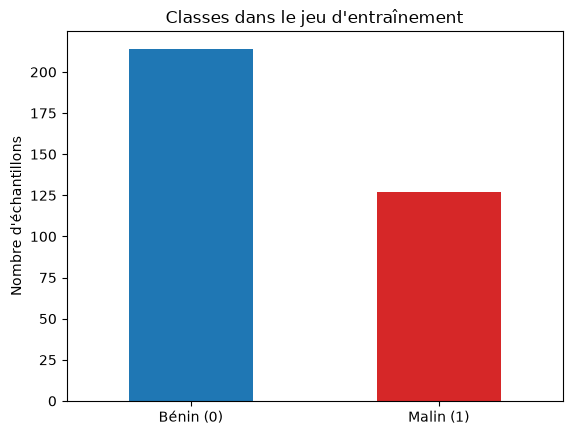

,mean,std,min,50%,max
radius_mean,14.127842,3.505235,7.760000,13.400000,27.22000
texture_mean,19.447214,4.501686,9.710000,19.020000,39.28000
perimeter_mean,91.960029,24.188431,47.920000,87.190000,182.10000
area_mean,654.334018,346.989868,181.000000,553.500000,2250.00000
smoothness_mean,0.096346,0.014300,0.052630,0.095870,0.16340
compactness_mean,0.104173,0.054216,0.023440,0.089950,0.34540
concavity_mean,0.087772,0.081053,0.000000,0.058920,0.42680
concave points_mean,0.048706,0.039857,0.000000,0.030850,0.20120
symmetry_mean,0.182020,0.028218,0.106000,0.179400,0.30400
fractal_dimension_mean,0.062833,0.007090,0.050250,0.061710,0.09744


In [5]:
train = pd.DataFrame(X_train, columns=noms_features)
effectifs = pd.Series(y_train).value_counts().reindex([0, 1], fill_value=0)
print('Référence majoritaire sur entraînement :', round(effectifs.max() / len(y_train), 3))
effectifs.plot(kind='bar', color=['tab:blue', 'tab:red'])
plt.xticks([0, 1], ['Bénin (0)', 'Malin (1)'], rotation=0)
plt.ylabel("Nombre d'échantillons")
plt.title("Classes dans le jeu d'entraînement")
plt.show()

train.describe().T[['mean', 'std', 'min', '50%', 'max']]

Le jeu d'entraînement contient davantage de cas bénins que de cas malins. Prédire toujours la classe majoritaire donne donc déjà une exactitude assez élevée, sans reconnaître de cancer. Cette référence sera comparée aux modèles sur le test final.

Les mesures n'ont pas les mêmes échelles : une surface prend des valeurs bien plus grandes qu'une mesure de régularité du contour. Comme la correction du perceptron contient le terme `erreur × feature`, cette différence influence directement l'apprentissage.

### Statistiques descriptives par classe

On calcule les effectifs, la moyenne, l'écart-type, les quartiles et les valeurs extrêmes pour chacune des 30 mesures, séparément pour les diagnostics bénins et malins. Toutes les lignes ci-dessous appartiennent à l'entraînement.


In [6]:
train_classes = train.copy()
train_classes['diagnostic'] = pd.Series(y_train).map({0: 'B', 1: 'M'})
statistiques_classes = train_classes.groupby('diagnostic')[noms_features].describe().T
statistiques_classes.columns = ['Bénin (B)', 'Malin (M)']
with pd.option_context('display.max_rows', 250):
    display(statistiques_classes.round(3))


Bénin (B)  Malin (M)
radius_mean             count    214.000    127.000
                        mean      12.146     17.467
                        std        1.812      3.113
                        min        7.760     11.420
                        25%       11.060     15.250
                        50%       12.180     17.190
                        75%       13.330     19.530
                        max       16.840     27.220
texture_mean            count    214.000    127.000
                        mean      17.890     22.072
                        std        3.982      4.100
                        min        9.710     10.380
                        25%       14.972     19.900
                        50%       17.345     21.820
                        75%       19.638     24.485
                        max       30.720     39.280
perimeter_mean          count    214.000    127.000
                        mean      78.040    115.416
                        std       12.013     21.242
                        min       47.920     77.580
                        25%       70.700    100.250
                        50%       77.810    112.800
                        75%       86.022    129.000
                        max      108.400    182.100
area_mean               count    214.000    127.000
                        mean     463.064    976.631
                        std      137.600    355.039
                        min      181.000    386.100
                        25%      373.375    714.950
                        50%      453.450    928.300
                        75%      549.925   1182.500
                        max      880.200   2250.000
smoothness_mean         count    214.000    127.000
                        mean       0.092      0.104
                        std        0.013      0.013
                        min        0.053      0.078
                        25%        0.084      0.095
                        50%        0.091      0.102
                        75%        0.100      0.111
                        max        0.163      0.145
compactness_mean        count    214.000    127.000
                        mean       0.079      0.147
                        std        0.034      0.055
                        min        0.023      0.046
                        25%        0.053      0.112
                        50%        0.072      0.132
                        75%        0.095      0.169
                        max        0.224      0.345
concavity_mean          count    214.000    127.000
                        mean       0.043      0.163
                        std        0.040      0.077
                        min        0.000      0.024
                        25%        0.020      0.109
                        50%        0.033      0.149
                        75%        0.055      0.208
                        max        0.313      0.427
concave points_mean     count    214.000    127.000
                        mean       0.025      0.089
                        std        0.015      0.036
                        min        0.000      0.020
                        25%        0.015      0.066
                        50%        0.023      0.086
                        75%        0.030      0.105
                        max        0.085      0.201
symmetry_mean           count    214.000    127.000
                        mean       0.174      0.196
                        std        0.025      0.029
                        min        0.106      0.131
                        25%        0.158      0.178
                        50%        0.171      0.193
                        75%        0.188      0.212
                        max        0.260      0.304
fractal_dimension_mean  count    214.000    127.000
                        mean       0.063      0.063
                        std        0.007      0.008
                        min        0.053      0.050
                        25%

Les mesures de taille, comme le rayon, le périmètre et la surface, ont des moyennes plus élevées chez les cas malins. Les quartiles et les écarts-types montrent aussi une dispersion dans chaque classe. Une moyenne différente ne suffit donc pas à séparer tous les échantillons.

### Distributions des dix mesures moyennes

Chaque graphique compare B et M avec les mêmes bornes de classes. On affiche des densités pour comparer les formes malgré les effectifs différents.


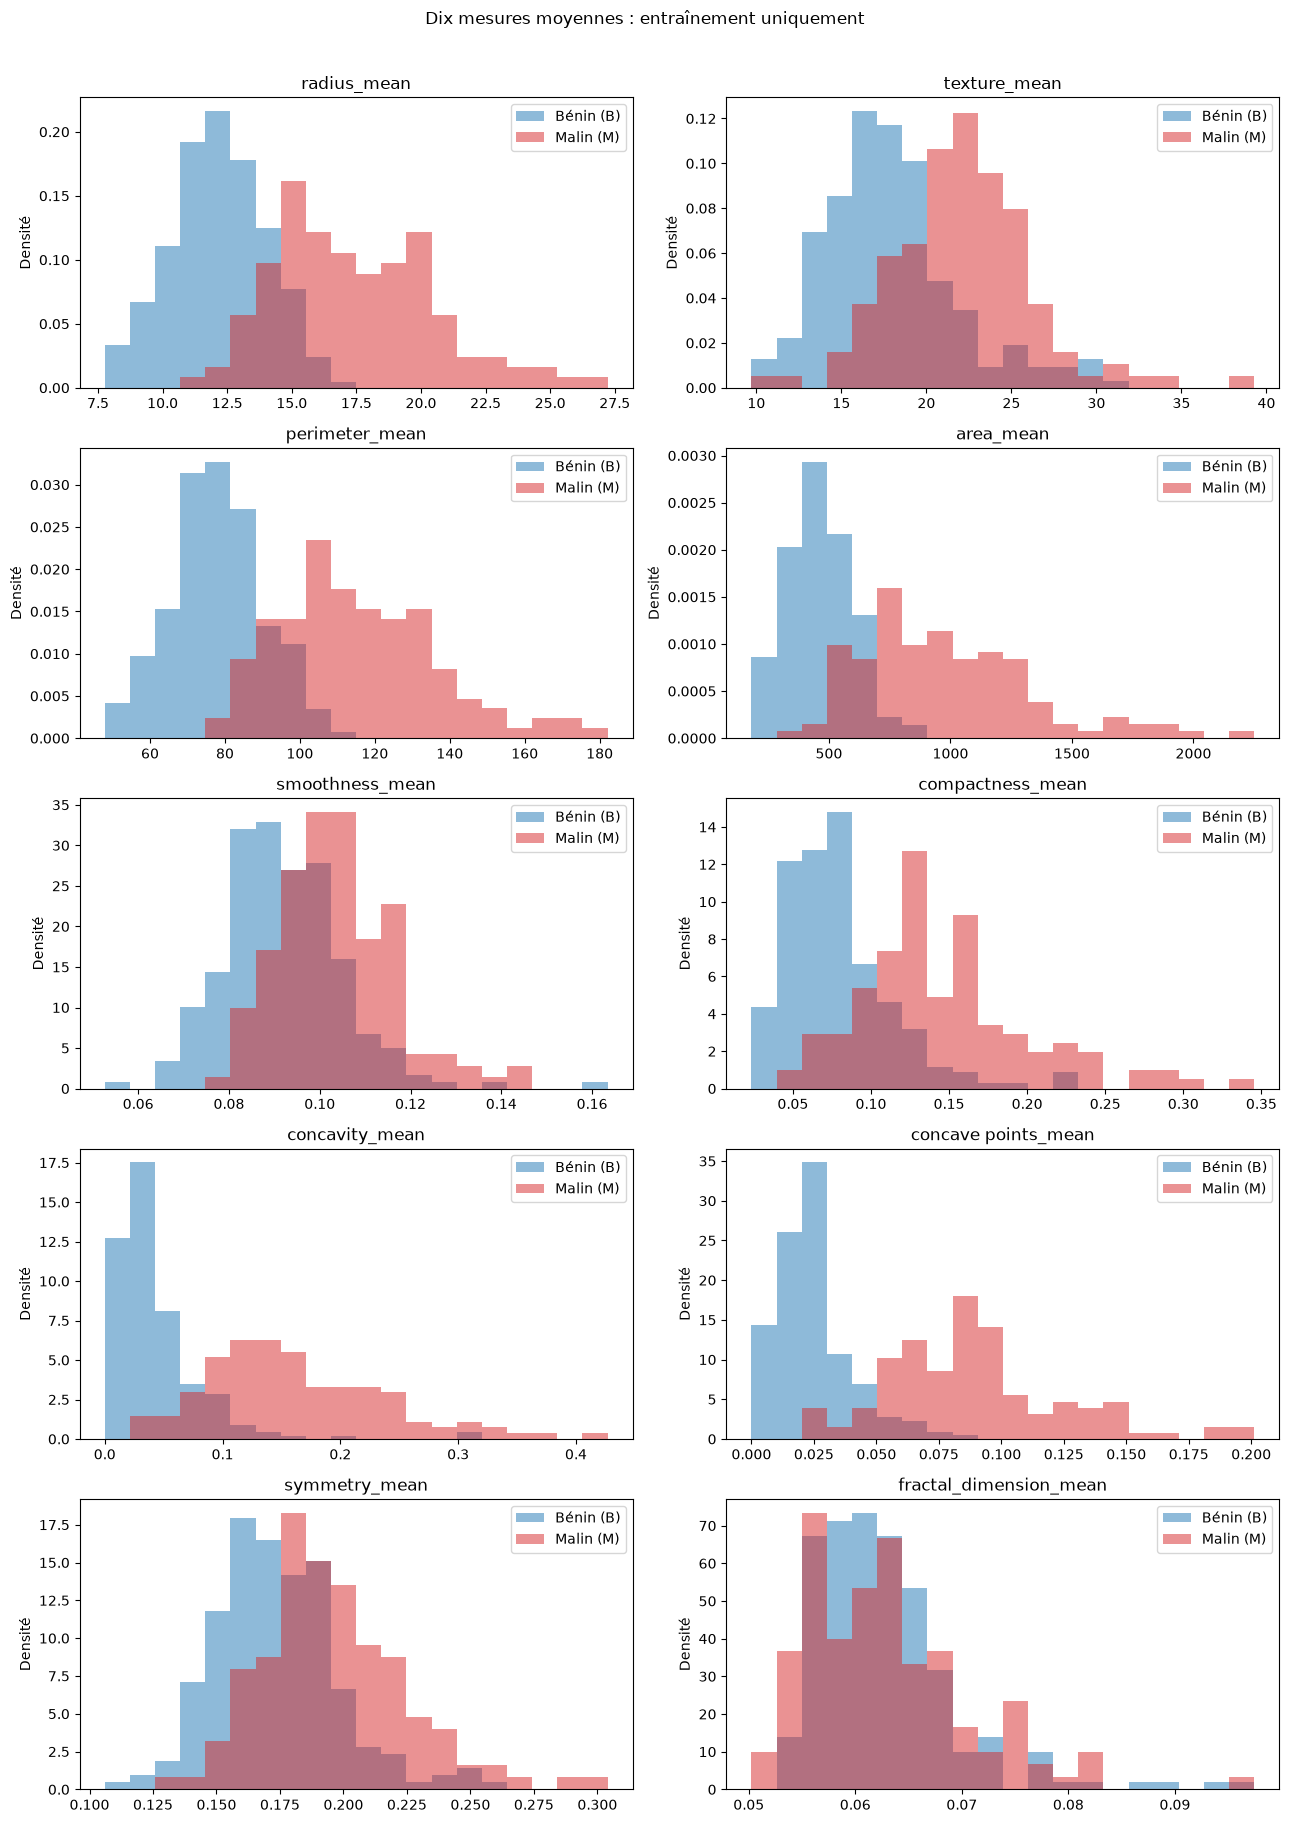

In [7]:
variables_mean = [nom for nom in noms_features if nom.endswith('_mean')]
assert len(variables_mean) == 10
fig, axes = plt.subplots(5, 2, figsize=(13, 18))
for ax, variable in zip(axes.flat, variables_mean):
    bornes = np.histogram_bin_edges(train[variable], bins=20)
    for classe, couleur, label in [(0, 'tab:blue', 'Bénin (B)'), (1, 'tab:red', 'Malin (M)')]:
        valeurs = train.loc[y_train == classe, variable]
        ax.hist(valeurs, bins=bornes, density=True, alpha=0.5, color=couleur, label=label)
    ax.set_title(variable)
    ax.set_ylabel('Densité')
    ax.legend()
fig.suptitle("Dix mesures moyennes : entraînement uniquement", y=1.01)
plt.tight_layout()
plt.show()


Les distributions des mesures de taille et de concavité se décalent vers des valeurs plus élevées pour les cas malins. La texture distingue moins nettement les groupes. La dimension fractale moyenne présente un fort chevauchement. Plusieurs distributions sont étirées vers les grandes valeurs.

Les chevauchements expliquent pourquoi une seule mesure ne suffit pas à prédire tous les diagnostics. Ils ne prouvent pas non plus qu'une séparation parfaite serait impossible avec les 30 mesures réunies.


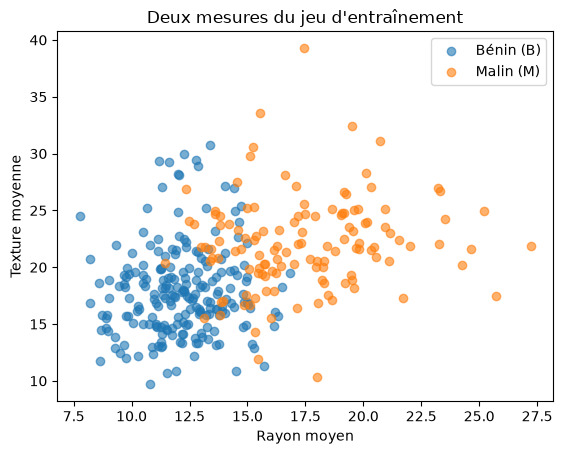

In [8]:
for classe, label in [(0, 'Bénin (B)'), (1, 'Malin (M)')]:
    groupe = train.loc[y_train == classe]
    plt.scatter(groupe['radius_mean'], groupe['texture_mean'], alpha=0.6, label=label)
plt.xlabel('Rayon moyen')
plt.ylabel('Texture moyenne')
plt.title("Deux mesures du jeu d'entraînement")
plt.legend()
plt.show()


Les cas malins se trouvent davantage du côté des grands rayons. Des points des deux classes occupent toutefois une zone commune. Une droite dans ce plan fera donc des erreurs. Le perceptron utilisera plus de deux mesures : cette projection ne décrit pas toute sa frontière.

### Boîtes à moustaches et valeurs extrêmes

La boîte va du premier au troisième quartile et son trait central représente la médiane. Les moustaches couvrent les observations situées à moins de 1,5 fois l'écart interquartile (IQR) des quartiles. Les points au-delà sont signalés comme extrêmes. Chaque mesure a son propre axe pour garder les unités d'origine.


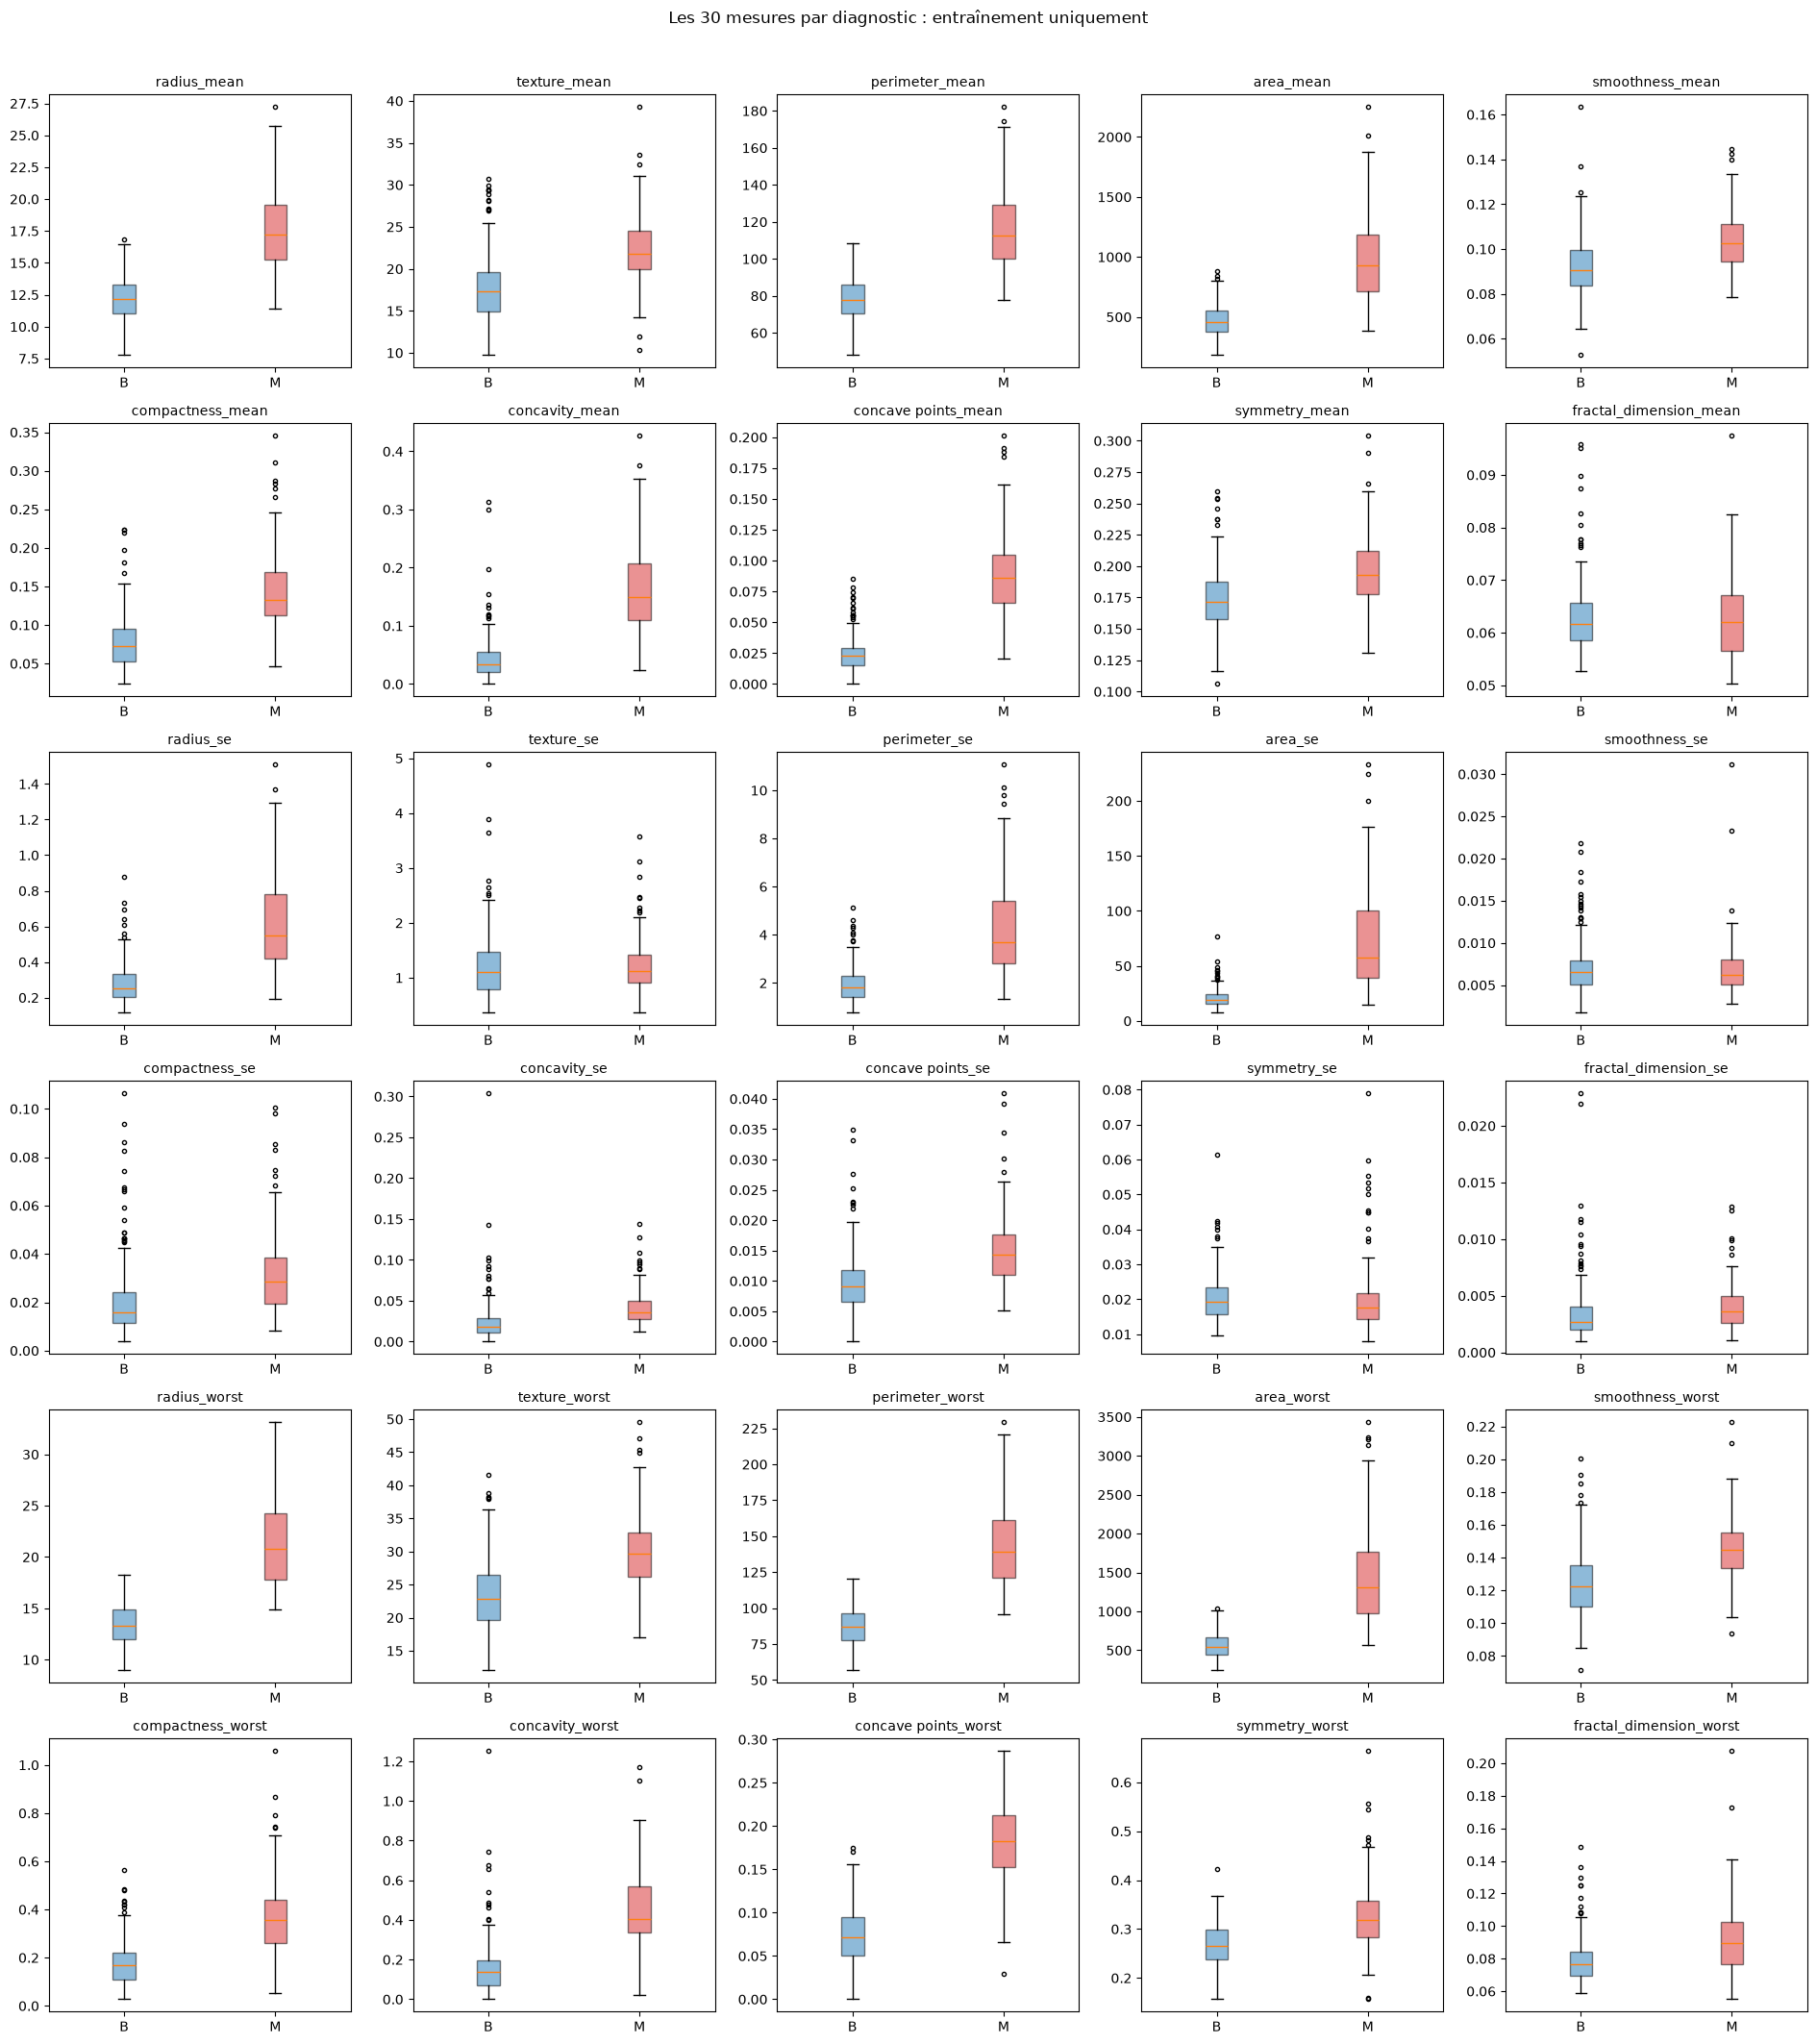

In [9]:
fig, axes = plt.subplots(6, 5, figsize=(19, 21))
for ax, variable in zip(axes.flat, noms_features):
    valeurs_classes = [train.loc[y_train == classe, variable] for classe in [0, 1]]
    boites = ax.boxplot(valeurs_classes, patch_artist=True, flierprops={'markersize': 3})
    for boite, couleur in zip(boites['boxes'], ['tab:blue', 'tab:red']):
        boite.set_facecolor(couleur)
        boite.set_alpha(0.5)
    ax.set_xticks([1, 2], ['B', 'M'])
    ax.set_title(variable, fontsize=10)
fig.suptitle("Les 30 mesures par diagnostic : entraînement uniquement", y=1.01)
plt.tight_layout()
plt.show()


Les médianes des mesures de taille et de concavité sont souvent plus élevées pour M. Les boîtes se recouvrent pour d'autres mesures. On observe des valeurs extrêmes dans les deux classes, surtout dans les distributions étirées vers la droite.

Les boîtes calculent leurs limites dans chaque classe. Pour avoir un comptage commun par variable, on calcule maintenant les bornes IQR sur tout l'entraînement, puis on compte les dépassements pour B et M avec ces mêmes bornes.


In [10]:
q1 = train.quantile(0.25)
q3 = train.quantile(0.75)
iqr = q3 - q1
masque_extremes = (train < q1 - 1.5 * iqr) | (train > q3 + 1.5 * iqr)
comptage_extremes = pd.DataFrame({
    'total': masque_extremes.sum(),
    'B': masque_extremes.loc[y_train == 0].sum(),
    'M': masque_extremes.loc[y_train == 1].sum()
}).sort_values('total', ascending=False)
print('Échantillons avec au moins une valeur extrême :',
      int(masque_extremes.any(axis=1).sum()), 'sur', len(train))
display(comptage_extremes)


Échantillons avec au moins une valeur extrême : 107 sur 341


,total,B,M
area_se,43,0,43
radius_se,27,1,26
perimeter_se,26,0,26
area_worst,26,0,26
concavity_se,21,8,13
symmetry_se,21,9,12
compactness_se,17,8,9
area_mean,17,0,17
smoothness_se,17,14,3
fractal_dimension_se,17,11,6


On conserve ces valeurs. Il s'agit de mesures réelles de cellules, et la règle IQR ne permet pas de conclure à une erreur de saisie. De grandes valeurs peuvent justement caractériser des tumeurs malignes. Les supprimer ou les plafonner ferait perdre cette information et modifierait les cas que le modèle doit apprendre à reconnaître.


### Les features apportent-elles des informations différentes ?

Une corrélation de Pearson proche de 1 ou de -1 indique une forte liaison linéaire entre deux mesures. Elle peut signaler de la redondance, sans suffire à décider de supprimer une variable. Une valeur proche de zéro n'exclut pas une relation non linéaire.

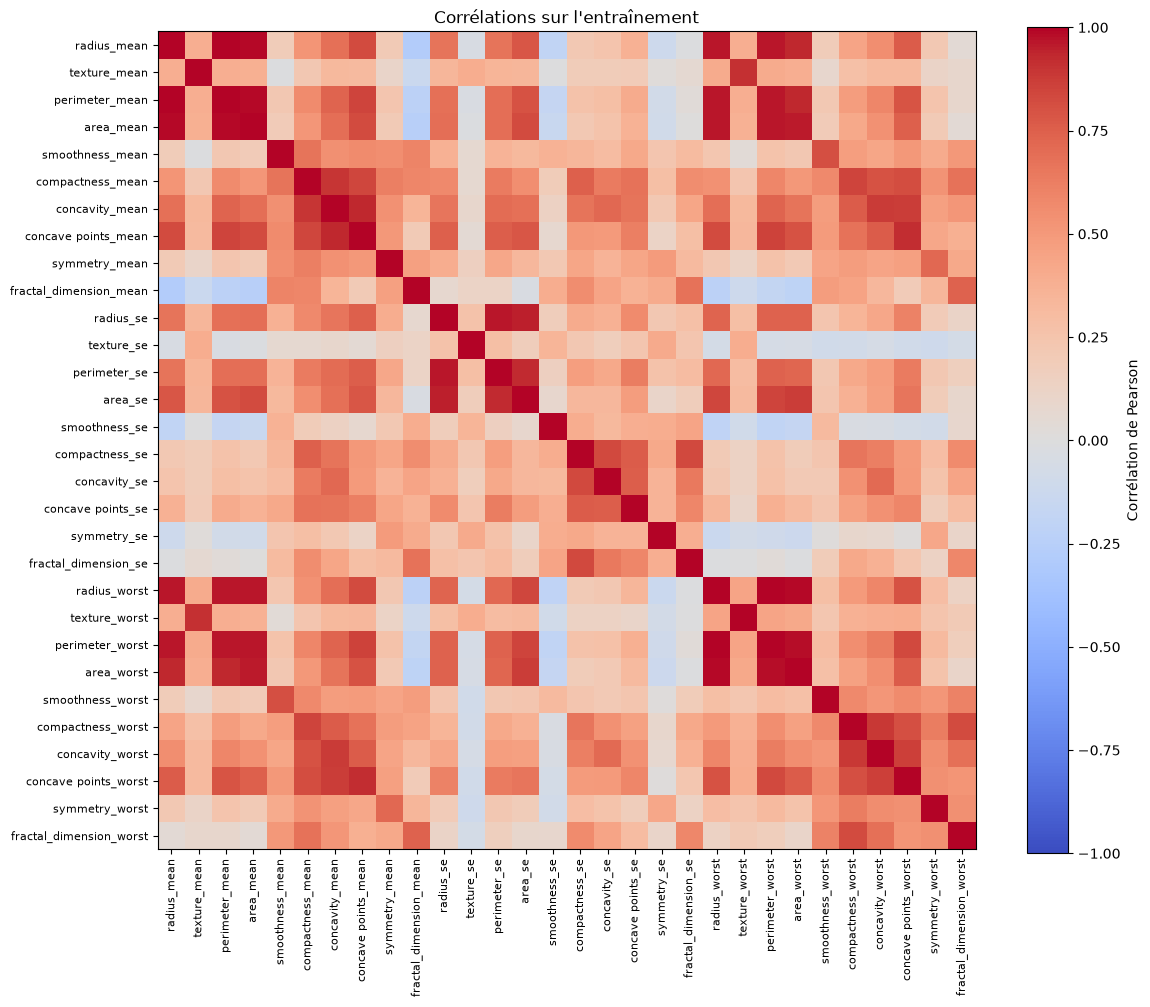

,feature_1,feature_2,correlation
0,radius_mean,perimeter_mean,0.997677
1,radius_mean,area_mean,0.989438
2,radius_mean,radius_worst,0.966351
3,radius_mean,perimeter_worst,0.963479
4,perimeter_mean,area_mean,0.988224
5,perimeter_mean,radius_worst,0.965265
6,perimeter_mean,perimeter_worst,0.968047
7,area_mean,radius_worst,0.964046
8,area_mean,perimeter_worst,0.961376
9,area_mean,area_worst,0.955749


In [11]:
correlations = train.corr()
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(noms_features)), labels=noms_features, rotation=90, fontsize=8)
ax.set_yticks(range(len(noms_features)), labels=noms_features, fontsize=8)
fig.colorbar(image, ax=ax, label='Corrélation de Pearson')
ax.set_title("Corrélations sur l'entraînement")
plt.tight_layout()
plt.show()

couples = []
for i in range(len(noms_features)):
    for j in range(i + 1, len(noms_features)):
        correlation = correlations.iloc[i, j]
        if abs(correlation) > 0.95:
            couples.append({'feature_1': noms_features[i],
                            'feature_2': noms_features[j],
                            'correlation': correlation})
pd.DataFrame(couples, columns=['feature_1', 'feature_2', 'correlation'])

Le rayon, le périmètre et la surface sont fortement corrélés, car ils décrivent tous la taille. Certaines versions `_mean` et `_worst` d'une même mesure sont aussi proches. Cela motive une réduction de dimension, sans garantir qu'elle améliorera les prédictions.

On garde les 30 mesures comme référence. On comparera ensuite une sélection de variables d'origine avec Boruta, puis une PCA qui construit de nouvelles composantes. Les deux méthodes seront ajustées uniquement sur l'entraînement.


## 6. Standardiser sans utiliser les données de validation ou de test

Pour chaque feature, on calcule `x_standardisé = (x − moyenne_train) / écart_type_train`. Les paramètres sont calculés uniquement sur l'entraînement, puis appliqués tels quels aux autres jeux.

Si une colonne est constante dans l'entraînement, son écart-type est remplacé par 1 pour éviter une division par zéro. On conserve les tableaux bruts et on crée de nouveaux tableaux standardisés.

In [12]:
moyennes_train = X_train.mean(axis=0)
ecarts_types_train = X_train.std(axis=0)
ecarts_types_train[ecarts_types_train == 0] = 1

X_train_std = (X_train - moyennes_train) / ecarts_types_train
X_val_std = (X_val - moyennes_train) / ecarts_types_train
X_test_std = (X_test - moyennes_train) / ecarts_types_train

controle = pd.DataFrame({
    'feature': noms_features,
    'moyenne_train_standardisee': X_train_std.mean(axis=0),
    'ecart_type_train_standardise': X_train_std.std(axis=0)
})
controle.round(6)

,feature,moyenne_train_standardisee,ecart_type_train_standardise
0,radius_mean,-0.0,1.0
1,texture_mean,-0.0,1.0
2,perimeter_mean,-0.0,1.0
3,area_mean,-0.0,1.0
4,smoothness_mean,0.0,1.0
5,compactness_mean,0.0,1.0
6,concavity_mean,-0.0,1.0
7,concave points_mean,-0.0,1.0
8,symmetry_mean,-0.0,1.0
9,fractal_dimension_mean,-0.0,1.0


## 7. Vérifier que les données sont prêtes pour notre classe

Les trois jeux doivent être distincts, les valeurs finies et les cibles binaires. L'ordre des 30 features doit rester identique partout. Les moyennes standardisées de l'entraînement sont proches de zéro ; celles de validation et de test ne sont pas forcées à zéro.

In [13]:
tous_indices = np.concatenate([indices_train, indices_val, indices_test])
assert len(np.unique(tous_indices)) == len(y)
assert len(tous_indices) == len(y)
assert np.allclose(X_train_std.mean(axis=0), 0)

for entrees, cibles in [(X_train_std, y_train), (X_val_std, y_val), (X_test_std, y_test)]:
    assert entrees.shape == (len(cibles), len(noms_features))
    assert np.isfinite(entrees).all()
    assert set(np.unique(cibles)) == {0, 1}

print('Données prêtes : 30 features, cible binaire et trois jeux distincts.')
print('Entraînement :', X_train_std.shape)
print('Validation :', X_val_std.shape)
print('Test :', X_test_std.shape)

Données prêtes : 30 features, cible binaire et trois jeux distincts.
Entraînement : (341, 30)
Validation : (113, 30)
Test : (115, 30)


## 8. Réduire le nombre de dimensions sur l'entraînement

### 8.1. Sélection avec Boruta

Boruta compare les variables à des copies mélangées, qui servent de référence aléatoire. Une forêt aléatoire mesure leur importance à chaque itération. On conserve seulement les variables confirmées ; les variables indécises restent écartées selon une règle fixée à l'avance.

Comme Pierre, on utilise une forêt de profondeur maximale 5 et au plus 100 itérations. La profondeur limitée évite des arbres trop complexes. Le nombre d'arbres est choisi automatiquement par Boruta. Les graines sont fixées à 42. Ces paramètres ne sont pas recherchés sur la validation. La forêt travaille sur les données brutes, car les arbres n'ont pas besoin de standardisation.


In [14]:
from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

foret = RandomForestClassifier(max_depth=5, random_state=42, n_jobs=-1)
boruta = BorutaPy(foret, n_estimators='auto', max_iter=100, random_state=42)
boruta.fit(X_train, y_train)

noms_array = np.array(noms_features)
confirmees = noms_array[boruta.support_].tolist()
indecises = noms_array[boruta.support_weak_].tolist()
rejetees = noms_array[~(boruta.support_ | boruta.support_weak_)].tolist()
assert len(confirmees) > 0, 'Boruta ne confirme aucune variable.'
print('Variables confirmées :', len(confirmees), confirmees)
print('Variables indécises :', indecises)
print('Variables rejetées :', rejetees)


Variables confirmées : 24 ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'radius_se', 'perimeter_se', 'area_se', 'concavity_se', 'concave points_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Variables indécises : ['fractal_dimension_mean']
Variables rejetées : ['symmetry_mean', 'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se']


Boruta conserve des variables associées au diagnostic, mais plusieurs peuvent apporter une information proche. Une variable rejetée n'est pas forcément inutile dans toute situation : cette décision dépend de la forêt et de notre échantillon d'entraînement. La sélection supervisée par une forêt peut aussi convenir différemment à un perceptron linéaire.

### 8.2. Retirer les variables très redondantes

On reprend le filtre de Pierre : classer les variables confirmées par importance, puis garder une variable seulement si sa corrélation absolue avec chacune des variables déjà gardées ne dépasse pas 0,90. Ce seuil fixe vise les redondances fortes. Il n'est pas ajusté avec la validation ou le test.

La forêt qui fournit cet ordre et la matrice de corrélation utilisent seulement l'entraînement. Ce filtre réduit la redondance linéaire ; il ne garantit pas que les variables restantes soient indépendantes ou que la performance augmente.


In [15]:
foret_importance = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
foret_importance.fit(train[confirmees], y_train)
importances = pd.Series(foret_importance.feature_importances_, index=confirmees)
importances = importances.sort_values(ascending=False, kind='stable')
correlations_boruta = train[confirmees].corr().abs()
seuil_correlation = 0.90
variables_boruta = []
variables_redondantes = []
for variable in importances.index:
    if all(correlations_boruta.loc[variable, gardee] <= seuil_correlation
           for gardee in variables_boruta):
        variables_boruta.append(variable)
    else:
        variables_redondantes.append(variable)

indices_boruta = [noms_features.index(nom) for nom in variables_boruta]
X_train_boruta = X_train_std[:, indices_boruta]
X_val_boruta = X_val_std[:, indices_boruta]
print('Après Boruta :', len(confirmees), 'variables')
print('Après le filtre de corrélation :', len(variables_boruta), 'variables')
print('Variables retirées pour redondance :', variables_redondantes)
display(importances.loc[variables_boruta].rename('importance').to_frame())


Après Boruta : 24 variables
Après le filtre de corrélation : 15 variables
Variables retirées pour redondance : ['concave points_mean', 'perimeter_worst', 'area_worst', 'perimeter_mean', 'area_mean', 'radius_mean', 'radius_se', 'texture_worst', 'perimeter_se']


,importance
concave points_worst,0.137808
radius_worst,0.111769
area_se,0.049738
concavity_worst,0.045249
concavity_mean,0.041310
compactness_mean,0.013923
compactness_worst,0.013728
texture_mean,0.012540
symmetry_worst,0.011512
smoothness_worst,0.010689


Les variables retenues gardent leur sens d'origine. On peut donc encore expliquer le modèle à partir de mesures cellulaires. On récupère leurs colonnes dans les tableaux déjà standardisés : les moyennes et les écarts-types restent ceux du train. Aucun nouveau paramètre n'est appris sur la validation.

### 8.3. Analyse en composantes principales (PCA)

La PCA est une autre approche : elle combine les 30 mesures standardisées en axes non corrélés sur le train. Elle utilise la variance des entrées, sans utiliser le diagnostic. On conserve le plus petit nombre de composantes qui atteint au moins 95 % de la variance d'entraînement.

Le seuil de 95 % est fixé avant la comparaison. Il garde l'essentiel de la variance tout en réduisant le nombre d'entrées. La variance ne mesure toutefois pas directement l'utilité pour reconnaître un cancer : une direction peu variable peut rester utile à la classification.


Composantes retenues : 10 sur 30
Variance conservée : 95.38%


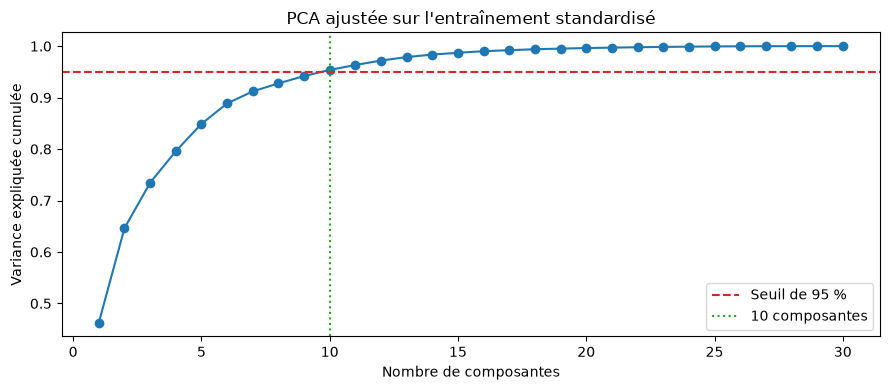

In [16]:
pca = PCA(svd_solver='full')
pca.fit(X_train_std)
variance_cumulee = np.cumsum(pca.explained_variance_ratio_)
n_composantes = int(np.searchsorted(variance_cumulee, 0.95) + 1)
X_train_pca = pca.transform(X_train_std)[:, :n_composantes]
X_val_pca = pca.transform(X_val_std)[:, :n_composantes]
print('Composantes retenues :', n_composantes, 'sur', X_train_std.shape[1])
print('Variance conservée :', f'{variance_cumulee[n_composantes - 1]:.2%}')

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(variance_cumulee) + 1), variance_cumulee, marker='o')
plt.axhline(0.95, color='tab:red', linestyle='--', label='Seuil de 95 %')
plt.axvline(n_composantes, color='tab:green', linestyle=':', label=f'{n_composantes} composantes')
plt.xlabel('Nombre de composantes')
plt.ylabel('Variance expliquée cumulée')
plt.title("PCA ajustée sur l'entraînement standardisé")
plt.legend()
plt.tight_layout()
plt.show()


La courbe monte rapidement au début : les premières composantes résument une grande partie des variations. Cela rejoint les fortes corrélations observées entre les mesures. Le trait vertical indique le premier nombre de composantes qui atteint 95 %. On garde ce nombre pour le modèle, même si seules les deux premières composantes sont représentées ci-dessous.


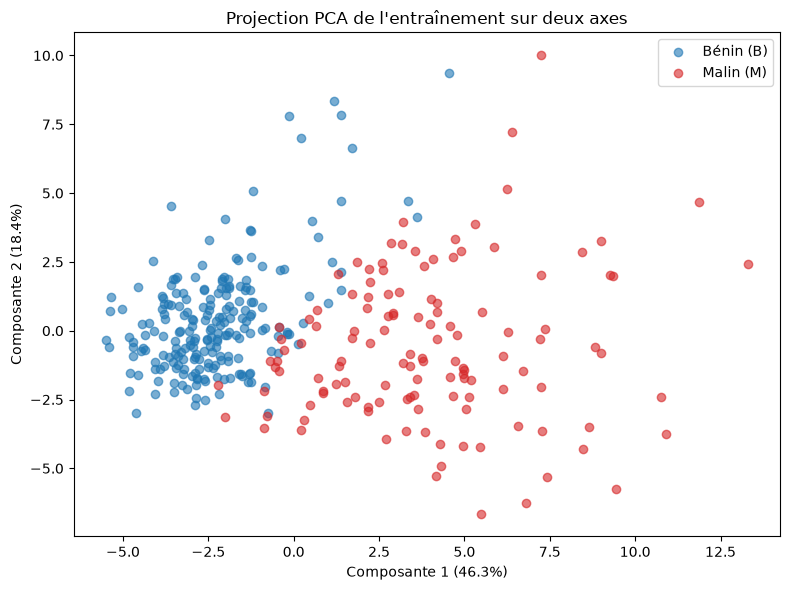

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))
for classe, couleur, label in [(0, 'tab:blue', 'Bénin (B)'), (1, 'tab:red', 'Malin (M)')]:
    ax.scatter(X_train_pca[y_train == classe, 0], X_train_pca[y_train == classe, 1],
               color=couleur, alpha=0.6, label=label)
ax.set_xlabel(f'Composante 1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'Composante 2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title("Projection PCA de l'entraînement sur deux axes")
ax.legend()
plt.tight_layout()
plt.show()


Les deux classes occupent des zones différentes sur le premier axe, avec un chevauchement près de la zone centrale. La projection montre une structure utile, sans assurer une séparation parfaite. Elle ne montre qu'une partie de la variance : le perceptron recevra toutes les composantes retenues à 95 %.

La PCA donne des entrées compactes, mais moins faciles à interpréter que les mesures gardées par Boruta. Les composantes ne sont pas à nouveau standardisées : on conserve leurs variances relatives après la standardisation initiale des mesures.


## 9. Entraîner et régler notre perceptron sur la validation

On importe la classe de `perceptron.py` sans la redéfinir. Pour chaque représentation, on compare une petite grille : `lr` dans `[0.001, 0.01, 0.1]` et `n_epochs` dans `[20, 50, 100]`. Chaque candidat apprend uniquement sur le train. L'ordre des exemples reste celui de notre séparation ; la classe ne les mélange pas entre les époques.

Le critère principal est le rappel des cas malins, aussi appelé sensibilité : `VP / (VP + FN)`. Un faux négatif est un cancer prédit bénin. On cherche donc d'abord à en manquer le moins possible. En cas d'égalité, on préfère le F1, puis l'exactitude, puis le moins d'époques et le plus petit taux d'apprentissage. Le F1 combine la précision et le rappel et évite de juger seulement la détection des cas malins.

Cette règle sert à choisir les réglages de chaque représentation et la représentation préférée sur validation. On ne réentraîne pas sur train + validation : on garde les trois modèles appris sur train pour la comparaison finale. Le test reste fermé jusqu'à la section 10.

Dans notre classe, les poids et le biais démarrent à zéro. En calcul exact, multiplier un taux positif par une constante multiplie aussi tous les poids et le biais et laisse les décisions identiques. Les trois taux de la grille sont donc en grande partie équivalents ; de petits écarts peuvent venir des arrondis numériques. Le nombre d'époques est ici le réglage le plus utile.


In [18]:
from perceptron import Perceptron
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

jeux_validation = {
    '30 variables': (X_train_std, X_val_std),
    'Boruta': (X_train_boruta, X_val_boruta),
    'PCA': (X_train_pca, X_val_pca)
}
modeles_retenus = {}
choix_validation = []
essais_validation = []
for nom, (entrees_train, entrees_val) in jeux_validation.items():
    candidats = []
    for lr in [0.001, 0.01, 0.1]:
        for n_epochs in [20, 50, 100]:
            modele = Perceptron(lr=lr, n_epochs=n_epochs)
            modele.fit(entrees_train, y_train)
            predictions_val = modele.predict(entrees_val)
            resultat = {
                'jeu': nom,
                'dimensions': entrees_train.shape[1],
                'lr': lr,
                'n_epochs': n_epochs,
                'rappel_val': recall_score(y_val, predictions_val, zero_division=0),
                'F1_val': f1_score(y_val, predictions_val, zero_division=0),
                'exactitude_val': modele.score(entrees_val, y_val)
            }
            essais_validation.append(resultat)
            candidats.append((resultat, modele))
    candidats.sort(key=lambda candidat: (
        -candidat[0]['rappel_val'], -candidat[0]['F1_val'],
        -candidat[0]['exactitude_val'], candidat[0]['n_epochs'], candidat[0]['lr']
    ))
    meilleur_resultat, meilleur_modele = candidats[0]
    choix_validation.append(meilleur_resultat)
    modeles_retenus[nom] = meilleur_modele

resultats_validation = pd.DataFrame(essais_validation)
display(resultats_validation.round(4))
comparaison_validation = pd.DataFrame(choix_validation).set_index('jeu')
classement_validation = comparaison_validation.sort_values(
    ['rappel_val', 'F1_val', 'exactitude_val', 'n_epochs', 'lr'],
    ascending=[False, False, False, True, True], kind='stable'
)
jeu_prefere = classement_validation.index[0]
print('Représentation préférée sur validation :', jeu_prefere)
print('En cas d’égalité complète entre représentations, on garde leur ordre de présentation.')
display(comparaison_validation.round(4))


,jeu,dimensions,lr,n_epochs,rappel_val,F1_val,exactitude_val
0,30 variables,30,0.001,20,0.9286,0.9398,0.9558
1,30 variables,30,0.001,50,0.9286,0.9176,0.9381
2,30 variables,30,0.001,100,0.9286,0.9398,0.9558
3,30 variables,30,0.010,20,0.9286,0.9398,0.9558
4,30 variables,30,0.010,50,0.9286,0.9176,0.9381
5,30 variables,30,0.010,100,0.9286,0.9398,0.9558
6,30 variables,30,0.100,20,0.9286,0.9398,0.9558
7,30 variables,30,0.100,50,0.9286,0.9176,0.9381
8,30 variables,30,0.100,100,0.9286,0.9398,0.9558
9,Boruta,15,0.001,20,0.9286,0.9630,0.9735


Représentation préférée sur validation : Boruta
En cas d’égalité complète entre représentations, on garde leur ordre de présentation.


,dimensions,lr,n_epochs,rappel_val,F1_val,exactitude_val
jeu,,,,,,
30 variables,30,0.001,20,0.9286,0.9398,0.9558
Boruta,15,0.001,100,0.9524,0.9412,0.9558
PCA,10,0.001,50,0.9286,0.9398,0.9558


Le tableau montre les résultats de validation des neuf réglages pour chaque représentation. La seconde table ne garde que le meilleur réglage de chaque jeu selon la règle annoncée. La représentation préférée est choisie maintenant, avant toute évaluation du test. On ne changera plus les variables, les composantes ou les réglages après l'ouverture du test.

### Suivre les erreurs pendant l'apprentissage

`errors_` compte les prédictions fausses rencontrées pendant chaque passage sur le train, alors que les poids changent. Ce n'est donc ni une erreur de validation, ni le nombre d'erreurs du modèle final évalué une fois sur le train.


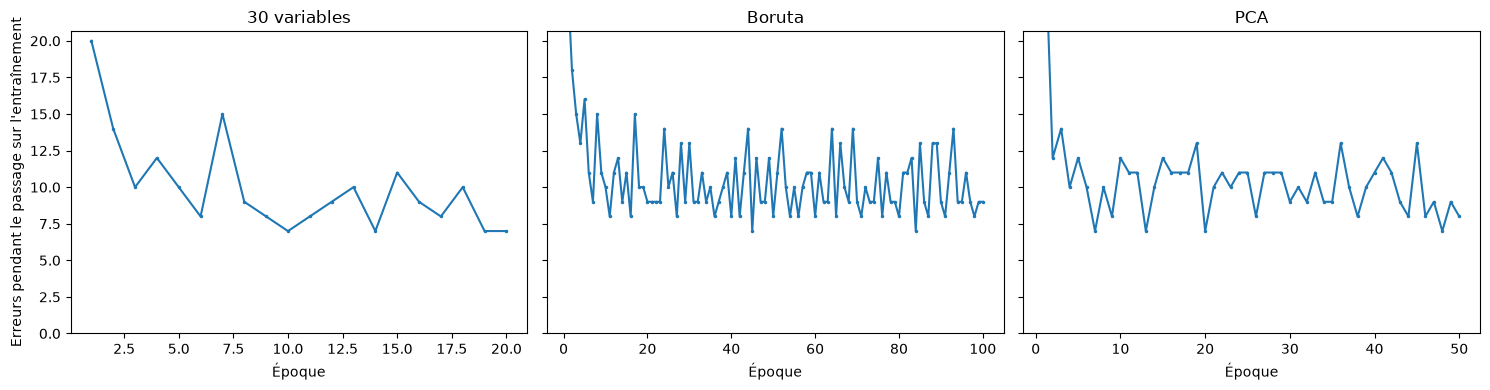

,erreurs_derniere_epoque,exactitude_train
jeu,,
30 variables,7,0.9824
Boruta,9,0.9677
PCA,8,0.9736


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (nom, modele) in zip(axes, modeles_retenus.items()):
    ax.plot(range(1, len(modele.errors_) + 1), modele.errors_, marker='.', markersize=3)
    ax.set_title(nom)
    ax.set_xlabel('Époque')
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Erreurs pendant le passage sur l'entraînement")
plt.tight_layout()
plt.show()

display(pd.DataFrame([
    {'jeu': nom, 'erreurs_derniere_epoque': modele.errors_[-1],
     'exactitude_train': modele.score(jeux_validation[nom][0], y_train)}
    for nom, modele in modeles_retenus.items()
]).set_index('jeu').round(4))


Les courbes permettent de voir si les corrections diminuent ou continuent à fluctuer. Une dernière époque avec des erreurs signifie que l'apprentissage ne s'est pas stabilisé sans correction dans le nombre de passages choisi. Cela ne prouve pas que les données soient impossibles à séparer : la limite d'époques et l'ordre fixe jouent aussi un rôle.

Le perceptron ne minimise pas directement le rappel ou le F1. On sélectionne ses réglages avec ces indicateurs sur validation, mais ses corrections restent celles de la classe fournie.


## 10. Évaluer une seule fois sur le test

Tous les choix sont figés. On applique maintenant les transformations apprises sur le train au test, puis chaque modèle produit une seule série de prédictions. On conserve ces prédictions pour tous les calculs et les graphiques ci-dessous.

La référence prédit toujours la classe la plus fréquente dans le train. Elle ne choisit pas sa classe à partir du test. Les métriques prennent M comme classe positive :

- Exactitude (accuracy) : proportion de diagnostics corrects.
- Précision : `VP / (VP + FP)`, part des prédictions malignes qui sont correctes.
- Rappel ou sensibilité : `VP / (VP + FN)`, part des cas malins détectés.
- Spécificité : `VN / (VN + FP)`, part des cas bénins reconnus.
- F1 : moyenne harmonique de la précision et du rappel.

Un faux négatif manque un cancer, tandis qu'un faux positif entraîne une alerte pour un cas bénin. Le rappel reste prioritaire dans cette comparaison. On rapporte aussi la spécificité et la précision pour rendre visible le coût des fausses alertes. Lorsqu'aucun cas malin n'est prédit, la précision et le F1 sont affichés à zéro par convention.


Modèle choisi sur validation, conservé après le test : Boruta


,dimensions,exactitude,precision,rappel,specificite,F1,VN,FP,FN,VP
jeu,,,,,,,,,,
30 variables,30,0.9826,0.9767,0.9767,0.9861,0.9767,71,1,1,42
Boruta,15,0.9652,0.9756,0.9302,0.9861,0.9524,71,1,3,40
PCA,10,0.9826,1.0000,0.9535,1.0000,0.9762,72,0,2,41
Classe majoritaire,0,0.6261,0.0000,0.0000,1.0000,0.0000,72,0,43,0


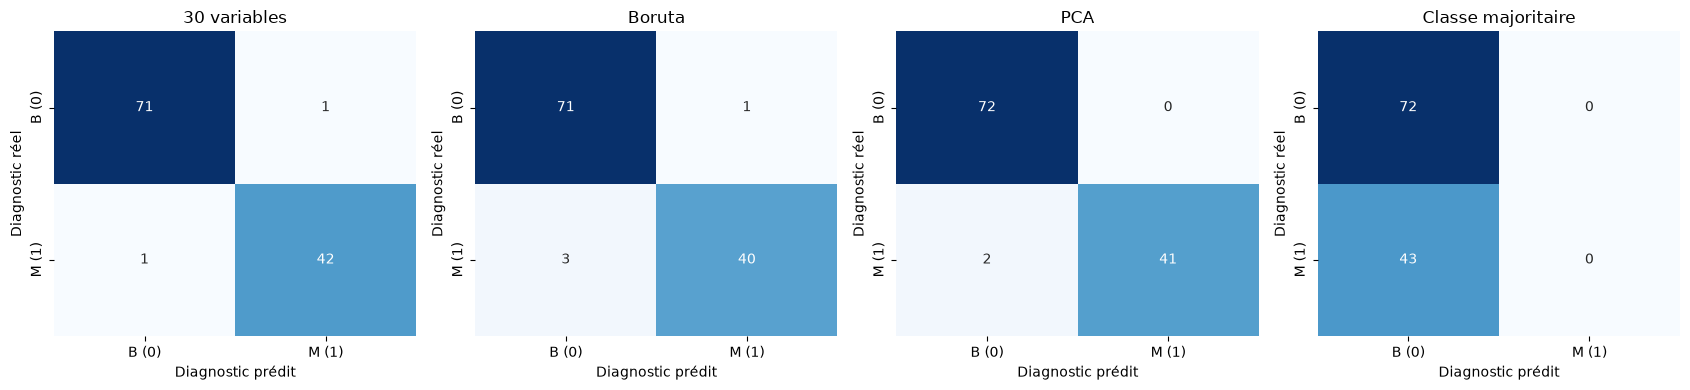

In [20]:
import seaborn as sns

# Premier et unique passage des modèles retenus sur le test.
X_test_boruta = X_test_std[:, indices_boruta]
X_test_pca = pca.transform(X_test_std)[:, :n_composantes]
jeux_test = {
    '30 variables': X_test_std,
    'Boruta': X_test_boruta,
    'PCA': X_test_pca
}
predictions_test = {}
for nom, modele in modeles_retenus.items():
    predictions_test[nom] = modele.predict(jeux_test[nom])
classe_majoritaire = int(np.argmax(np.bincount(y_train)))
predictions_test['Classe majoritaire'] = np.full(len(y_test), classe_majoritaire, dtype=int)

matrices_test = {}
resultats_test = []
for nom, predictions in predictions_test.items():
    matrice = confusion_matrix(y_test, predictions, labels=[0, 1])
    matrices_test[nom] = matrice
    vn, fp, fn, vp = matrice.ravel()
    resultats_test.append({
        'jeu': nom,
        'dimensions': jeux_test[nom].shape[1] if nom in jeux_test else 0,
        'exactitude': accuracy_score(y_test, predictions),
        'precision': precision_score(y_test, predictions, zero_division=0),
        'rappel': recall_score(y_test, predictions, zero_division=0),
        'specificite': vn / (vn + fp),
        'F1': f1_score(y_test, predictions, zero_division=0),
        'VN': int(vn), 'FP': int(fp), 'FN': int(fn), 'VP': int(vp)
    })
comparaison_test = pd.DataFrame(resultats_test).set_index('jeu')
print('Modèle choisi sur validation, conservé après le test :', jeu_prefere)
display(comparaison_test.round(4))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (nom, matrice) in zip(axes, matrices_test.items()):
    sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['B (0)', 'M (1)'], yticklabels=['B (0)', 'M (1)'], ax=ax)
    ax.set_title(nom)
    ax.set_xlabel('Diagnostic prédit')
    ax.set_ylabel('Diagnostic réel')
plt.tight_layout()
plt.show()


Chaque matrice se lit avec le diagnostic réel en ligne et la prédiction en colonne. La case en bas à gauche compte les faux négatifs, donc les cancers manqués. La case en haut à droite compte les fausses alertes. La référence majoritaire peut obtenir une exactitude assez élevée, mais son rappel des cas malins est nul puisqu'elle prédit toujours B.

Les trois perceptrons sont comparés sur les mêmes échantillons. Réduire la dimension n'assure pas une amélioration : Boruta peut retirer une information utile au modèle linéaire, et la PCA privilégie la variance plutôt que le diagnostic. Le test décrit les résultats des choix déjà faits ; il ne sert pas à sélectionner un autre réglage ou une autre représentation.


## 11. Vérifier la stabilité avec une validation croisée

Les résultats précédents reposent sur un seul découpage. Avec 113 échantillons en validation et 115 en test, un ou deux cas suffisent à changer le classement des modèles. Une validation croisée stratifiée mesure cette variabilité.

On réunit l'entraînement et la validation, soit 454 échantillons, et on les découpe en 5 plis stratifiés. À chaque tour, 4 plis servent à l'apprentissage et le dernier à l'évaluation. Chaque échantillon est donc évalué une fois. Le test reste fermé : il a déjà servi une fois et ne sert plus.

Pour éviter les fuites de données, tout est réappris dans chaque pli, uniquement sur sa partie d'apprentissage : la standardisation, la sélection Boruta avec le filtre de corrélation, et la PCA à 95 % de variance. Le nombre de variables Boruta et de composantes PCA peut donc changer d'un pli à l'autre. Les réglages du perceptron (`lr` et `n_epochs`) restent ceux choisis à la section 9.

Ces réglages ont été choisis avec la validation, qui fait partie des plis. Les scores peuvent donc être légèrement optimistes. L'objectif ici est surtout de comparer la dispersion des trois représentations.

In [21]:
from sklearn.model_selection import StratifiedKFold


def selection_boruta(X_brut, y, noms, graine=42, seuil=0.90):
    """Boruta puis filtre de corrélation, appris uniquement sur les données reçues."""
    foret = RandomForestClassifier(max_depth=5, random_state=graine, n_jobs=-1)
    selecteur = BorutaPy(foret, n_estimators='auto', max_iter=100, random_state=graine)
    selecteur.fit(X_brut, y)
    confirmees = [nom for nom, garde in zip(noms, selecteur.support_) if garde]
    tableau = pd.DataFrame(X_brut, columns=noms)[confirmees]
    foret_importance = RandomForestClassifier(n_estimators=300, random_state=graine, n_jobs=-1)
    foret_importance.fit(tableau, y)
    ordre = pd.Series(foret_importance.feature_importances_, index=confirmees)
    ordre = ordre.sort_values(ascending=False, kind='stable').index
    correlations_pli = tableau.corr().abs()
    gardees = []
    for variable in ordre:
        if all(correlations_pli.loc[variable, gardee] <= seuil for gardee in gardees):
            gardees.append(variable)
    return [noms.index(nom) for nom in gardees]


def metriques(y_vrai, y_predit):
    vn, fp, fn, vp = confusion_matrix(y_vrai, y_predit, labels=[0, 1]).ravel()
    return {
        'exactitude': accuracy_score(y_vrai, y_predit),
        'precision': precision_score(y_vrai, y_predit, zero_division=0),
        'rappel': recall_score(y_vrai, y_predit, zero_division=0),
        'specificite': vn / (vn + fp),
        'F1': f1_score(y_vrai, y_predit, zero_division=0),
        'cancers_manques': int(fn),
        'cancers': int(fn + vp)
    }


X_dev = np.vstack([X_train, X_val])
y_dev = np.concatenate([y_train, y_val])
plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultats_cv = []
for numero, (indices_app, indices_eval) in enumerate(plis.split(X_dev, y_dev), start=1):
    X_app, X_eval = X_dev[indices_app], X_dev[indices_eval]
    y_app, y_eval = y_dev[indices_app], y_dev[indices_eval]

    # Standardisation apprise sur la partie d'apprentissage du pli
    moyennes_pli = X_app.mean(axis=0)
    ecarts_pli = X_app.std(axis=0)
    ecarts_pli[ecarts_pli == 0] = 1
    X_app_std = (X_app - moyennes_pli) / ecarts_pli
    X_eval_std = (X_eval - moyennes_pli) / ecarts_pli

    # Boruta et PCA réappris dans le pli
    indices_boruta_pli = selection_boruta(X_app, y_app, noms_features)
    pca_pli = PCA(svd_solver='full').fit(X_app_std)
    k = int(np.searchsorted(np.cumsum(pca_pli.explained_variance_ratio_), 0.95) + 1)

    jeux_pli = {
        '30 variables': (X_app_std, X_eval_std),
        'Boruta': (X_app_std[:, indices_boruta_pli], X_eval_std[:, indices_boruta_pli]),
        'PCA': (pca_pli.transform(X_app_std)[:, :k], pca_pli.transform(X_eval_std)[:, :k])
    }
    for nom, (entrees_app, entrees_eval) in jeux_pli.items():
        reglages = comparaison_validation.loc[nom]
        modele = Perceptron(lr=float(reglages['lr']), n_epochs=int(reglages['n_epochs']))
        modele.fit(entrees_app, y_app)
        resultats_cv.append({'pli': numero, 'jeu': nom, 'dimensions': entrees_app.shape[1],
                             **metriques(y_eval, modele.predict(entrees_eval))})

resultats_cv = pd.DataFrame(resultats_cv)
ordre_jeux = ['30 variables', 'Boruta', 'PCA']
colonnes = ['exactitude', 'precision', 'rappel', 'specificite', 'F1']

moyennes_cv = resultats_cv.groupby('jeu')[colonnes].mean().reindex(ordre_jeux)
ecarts_cv = resultats_cv.groupby('jeu')[colonnes].std().reindex(ordre_jeux)
resume_cv = (moyennes_cv * 100).round(1).astype(str) + ' ± ' + (ecarts_cv * 100).round(1).astype(str) + ' %'
resume_cv['entrées (min-max)'] = resultats_cv.groupby('jeu')['dimensions'].agg(
    lambda d: f'{d.min()}-{d.max()}').reindex(ordre_jeux)
resume_cv['cancers manqués'] = resultats_cv.groupby('jeu').apply(
    lambda g: f"{g['cancers_manques'].sum()} / {g['cancers'].sum()}", include_groups=False).reindex(ordre_jeux)

print('Moyenne ± écart-type sur les 5 plis :')
display(resume_cv)
print('Détail par pli :')
display(resultats_cv.pivot(index='pli', columns='jeu', values='rappel')[ordre_jeux].round(3))

Moyenne ± écart-type sur les 5 plis :


,exactitude,precision,rappel,specificite,F1,entrées (min-max),cancers manqués
jeu,,,,,,,
30 variables,94.3 ± 3.3 %,92.5 ± 5.8 %,92.3 ± 4.5 %,95.4 ± 3.6 %,92.3 ± 4.4 %,30-30,13 / 169
Boruta,94.3 ± 3.8 %,90.6 ± 6.2 %,94.7 ± 4.4 %,94.0 ± 4.0 %,92.5 ± 4.9 %,11-14,9 / 169
PCA,94.7 ± 3.3 %,92.0 ± 4.6 %,94.1 ± 5.5 %,95.1 ± 2.9 %,93.0 ± 4.5 %,10-10,10 / 169


Détail par pli :


jeu,30 variables,Boruta,PCA
pli,,,
1,0.882,0.882,0.853
2,0.882,0.971,0.971
3,0.971,0.941,0.941
4,0.971,1.000,1.000
5,0.909,0.939,0.939


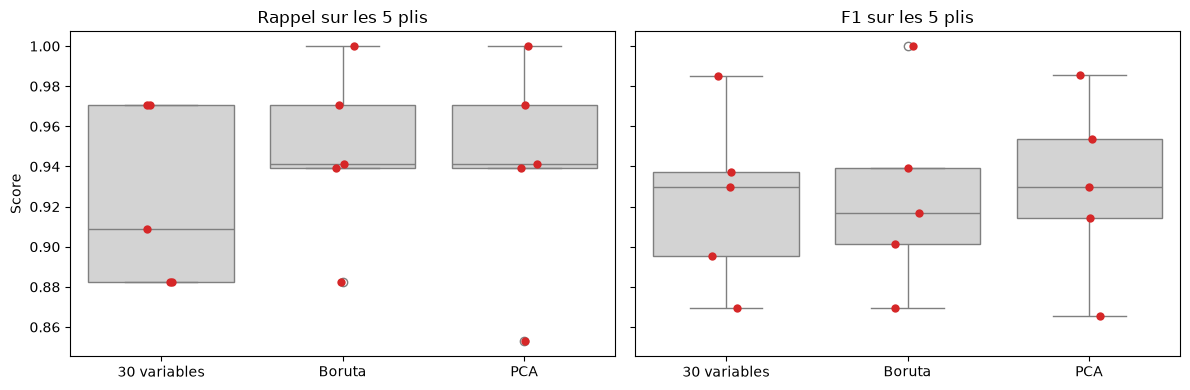

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metrique in zip(axes, ['rappel', 'F1']):
    sns.boxplot(data=resultats_cv, x='jeu', y=metrique, order=ordre_jeux, color='lightgray', ax=ax)
    sns.stripplot(data=resultats_cv, x='jeu', y=metrique, order=ordre_jeux, color='tab:red', size=6, ax=ax)
    ax.set_title(f'{metrique.capitalize()} sur les 5 plis')
    ax.set_xlabel('')
axes[0].set_ylabel('Score')
plt.tight_layout()
plt.show()

Sur les 5 plis, les trois représentations obtiennent environ 94 % d'exactitude et entre 92 % et 95 % de rappel. Les écarts entre leurs moyennes (2 à 3 points au plus) sont plus petits que leurs écarts-types (4 à 6 points). Aucune représentation n'est donc meilleure que les autres de façon fiable.

Le rappel varie surtout d'un pli à l'autre : de 0,85 à 1 selon les échantillons évalués. C'est l'effet de la petite taille des plis, qui contiennent chacun environ 34 cas malins.

Ces scores sont plus bas que ceux du test (98 % d'exactitude avec les 30 variables). Le découpage du test était donc plutôt favorable. Une estimation plus prudente des performances de notre perceptron est d'environ 94 % d'exactitude, avec 9 à 13 cancers manqués sur 169 selon la représentation.

La réduction de dimension garde des performances équivalentes avec moins d'entrées : 10 composantes pour la PCA, 11 à 14 variables pour Boruta selon les plis. Elle simplifie le modèle sans le dégrader.


## 12. Conclusion et pistes d'amélioration

Le nettoyage a retiré la colonne vide et l'identifiant des entrées. Les valeurs extrêmes ont été conservées. La séparation stratifiée, la standardisation calculée sur le train et les transformations apprises sur le train évitent d'utiliser le test pour préparer les modèles.

On a comparé le même perceptron avec les 30 mesures, les variables retenues par Boruta et le filtre de corrélation, puis les composantes de la PCA. La validation a servi à fixer les réglages et la représentation préférée. La validation croisée a ensuite mesuré la stabilité de ces résultats. Le tableau de test permet maintenant de discuter son efficacité, surtout avec le nombre de cancers manqués, puis avec les fausses alertes.


In [23]:
# Lecture des résultats déjà calculés, sans nouvelle prédiction ni nouveau choix.
for nom in jeux_test:
    ligne = comparaison_test.loc[nom]
    print(f"{nom} : {int(ligne['dimensions'])} entrées, "
          f"exactitude {ligne['exactitude']:.1%}, rappel {ligne['rappel']:.1%}, "
          f"spécificité {ligne['specificite']:.1%}, "
          f"{int(ligne['FN'])} cancers manqués sur {int(ligne['FN'] + ligne['VP'])}.")
ligne_preferee = comparaison_test.loc[jeu_prefere]
gain_exactitude = ligne_preferee['exactitude'] - comparaison_test.loc['Classe majoritaire', 'exactitude']
print(f"Le modèle choisi sur validation ({jeu_prefere}) a un F1 de {ligne_preferee['F1']:.3f} "
      f"et un écart d'exactitude de {gain_exactitude:+.1%} avec la référence majoritaire.")


30 variables : 30 entrées, exactitude 98.3%, rappel 97.7%, spécificité 98.6%, 1 cancers manqués sur 43.
Boruta : 15 entrées, exactitude 96.5%, rappel 93.0%, spécificité 98.6%, 3 cancers manqués sur 43.
PCA : 10 entrées, exactitude 98.3%, rappel 95.3%, spécificité 100.0%, 2 cancers manqués sur 43.
Le modèle choisi sur validation (Boruta) a un F1 de 0.952 et un écart d'exactitude de +33.9% avec la référence majoritaire.


Sur le test, le perceptron dépasse nettement la référence majoritaire, qui ne détecte aucun cancer. Avec les 30 mesures, il manque 1 cancer sur 43 et donne 1 fausse alerte sur 72 cas bénins (exactitude 98,3 %, rappel 97,7 %). La PCA à 10 composantes obtient la même exactitude, sans fausse alerte mais avec 2 cancers manqués. Boruta, préféré sur la validation pour un seul cas d'écart, manque 3 cancers sur le test : ce choix ne se confirme pas, ce qui montre la variabilité liée à la petite taille des jeux. La validation croisée le confirme : sur 5 plis, les trois représentations sont à égalité, autour de 94 % d'exactitude et 92 à 95 % de rappel, avec des écarts-types de 4 à 6 points. Le score du test est donc optimiste, et environ 94 % est une estimation plus réaliste. Un modèle linéaire aussi simple sépare donc déjà très bien ces données, mais chaque cancer manqué reste une erreur grave dans un contexte médical.

Le perceptron fournit une première méthode simple pour combiner les mesures avec une frontière linéaire. Son intérêt se juge face à la référence majoritaire : reconnaître seulement les cas bénins ne suffit pas. Même une bonne exactitude ne compense pas un rappel trop faible. Des corrections persistantes pendant l'apprentissage montrent aussi les limites du réglage retenu.

Le test repose sur une seule séparation, et la validation croisée montre que les scores varient nettement d'un découpage à l'autre. Ils dépendent aussi de l'ordre d'apprentissage. Une différence de quelques cas ne permet pas d'affirmer qu'une représentation est toujours meilleure. Les erreurs observées et cette incertitude limitent la portée du résultat.

Pour aller plus loin, on pourrait comparer les solutions suivantes, sans les implémenter ici :

- Une régression logistique, pour obtenir un score probabiliste et utiliser une régularisation.
- Un SVM linéaire ou avec noyau, pour chercher une séparation avec une marge ou une frontière non linéaire.
- Un perceptron multicouche (MLP), pour apprendre des relations non linéaires entre les mesures.
- Un ajustement du seuil sur la validation, pour privilégier la sensibilité en acceptant davantage de fausses alertes. Il faudrait d'abord exposer le score avant la décision dans notre classe, qui ne renvoie actuellement que 0 ou 1.
- Une validation croisée répétée ou imbriquée, pour choisir aussi les réglages à l'intérieur des plis et obtenir une estimation sans biais d'optimisme.
- Une pondération des classes ou des erreurs, pour rendre les faux négatifs plus coûteux pendant l'apprentissage. Notre classe devrait être adaptée pour cela.
- Un mélange reproductible des exemples à chaque époque, pour réduire la dépendance à leur ordre. Un arrêt anticipé ou la conservation des meilleurs poids pourrait aussi limiter les oscillations.

Ces pistes demanderaient une nouvelle phase de validation. Le test utilisé ici resterait une évaluation finale : on ne chercherait pas de nouveaux réglages à partir de ses erreurs.
